In [1]:
import numpy as np
import qiskit
import openfermion
import pyscf
from networkx.algorithms.bipartite.basic import density

In [2]:
# H4 molecule
from pyscf import gto, scf

# Build molecule
d=2.0
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 1*d)],
          ["H", (0.0, 0.0, 2*d)],
          ["H", (0.0, 0.0, 3*d)]
          ],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.57561647670187


np.float64(-1.575616476701867)

In [3]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
fci_energy, ci = cisolver.kernel()
print("FCI energy:", fci_energy)

FCI energy: -1.897780645989874


In [4]:
tol_ampl = 0.01

from pyscf.fci import cistring
mc = cisolver

ncas = mc.norb
nelec = mc.nelec

# determinants α i β (representats com enters amb bits d’ocupació)
na, nb = nelec
alpha_det = cistring.make_strings(range(ncas), na)
beta_det = cistring.make_strings(range(ncas), nb)


def interleave_bits(a, b, ncas):
    """Return interleaved occupation string (αβ αβ ...)"""
    a_bits = [(a >> i) & 1 for i in range(ncas)]
    b_bits = [(b >> i) & 1 for i in range(ncas)]
    inter = []
    for i in reversed(range(ncas)):
        inter.append(str(a_bits[i]))
        inter.append(str(b_bits[i]))
    return ''.join(inter)[::-1]

print('\namplitudes FCI')
for i, a in enumerate(alpha_det):
    for j, b in enumerate(beta_det):
        amp = mc.ci[i, j]
        if amp**2 > tol_ampl:
            # print(f"α={format(a, f'0{ncas}b')}  β={format(b, f'0{ncas}b')}  coef={amp:+.6f}")
            cfg = interleave_bits(a, b, ncas)
            print(f"{cfg}   {amp:+.6f}  ({amp**2:.6f}) ")


amplitudes FCI
11110000   +0.694100  (0.481775) 
11001100   -0.388924  (0.151262) 
01100110   -0.181096  (0.032796) 
00111100   -0.114150  (0.013030) 
10010110   -0.255203  (0.065128) 
01101001   -0.255203  (0.065128) 
11000011   -0.107524  (0.011561) 
10011001   -0.181096  (0.032796) 
00110011   -0.251266  (0.063134) 
00001111   +0.259514  (0.067347) 


In [5]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
# nuclear
print(e_nuc)

[[-1.13379714e+00 -4.09394740e-16  9.24693961e-02 -1.11022302e-16]
 [-4.57966998e-16 -1.04226825e+00 -5.55111512e-16 -7.41977398e-02]
 [ 9.24693961e-02 -5.55111512e-16 -9.78602165e-01 -4.16333634e-16]
 [-1.66533454e-16 -7.41977398e-02 -3.95516953e-16 -9.67108698e-01]]
[[[[ 3.50481811e-01 -2.25514052e-17 -5.76182543e-02  9.02056208e-17]
   [-3.46944695e-18  1.64643593e-01 -6.93889390e-18  3.03991509e-02]
   [-5.76182543e-02 -1.38777878e-17  1.27781482e-01  1.52655666e-16]
   [ 8.32667268e-17  3.03991509e-02  1.45716772e-16  1.23346862e-01]]

  [[-3.46944695e-18  1.64643593e-01 -6.93889390e-18  3.03991509e-02]
   [ 3.19106671e-01  2.15105711e-16  1.74272684e-02  2.08166817e-17]
   [ 1.38777878e-16  6.97056778e-02 -3.23525928e-16 -1.03951062e-01]
   [ 5.98408006e-02 -2.77555756e-17 -1.29023423e-01  2.53269627e-16]]

  [[-5.76182543e-02 -1.38777878e-17  1.27781482e-01  1.52655666e-16]
   [ 1.38777878e-16  6.97056778e-02 -3.23525928e-16 -1.03951062e-01]
   [ 3.22145549e-01 -3.88578059e-16  

In [6]:
from openfermion import InteractionOperator, jordan_wigner
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5*eri_so)
ha_qubit = jordan_wigner(hamiltonian)


In [7]:
from openfermion import FermionOperator
# a b a b a b
state = FermionOperator('0^ 1^ 2^ 3^')

In [8]:
from scipy.sparse.linalg import expm, expm_multiply


def time_evolution_trotter(t):
    vec = get_sparse_operator(state, n_qubits=8)
    for op in ha_qubit.get_operators():
        sparse_op =-1j*t * get_sparse_operator(op, n_qubits=8)
        vec = expm_multiply(sparse_op, vec)
    return vec

In [9]:
from qiskit_addon_sqd.fermion import solve_fermion


def get_sci_energy(configuration_list):

    up_list = []
    down_list = []
    for fock_vector in configuration_list:

        bitstring = ''.join(str(bit) for bit in fock_vector)

        up_str = ''.join(
            '0' if i % 2 == 0 else bit
            for i, bit in enumerate(bitstring)
        )

        down_str = ''.join(
            bit if i % 2 == 0 else '0'
            for i, bit in enumerate(bitstring)
        )

        up_list.append(int(up_str, 2))
        down_list.append(int(down_str, 2))

    up = np.array(up_list, dtype=np.uint32)
    down = np.array(down_list, dtype=np.uint32)

    inv = np.argsort((0, 2, 3, 1))
    # Hamiltonian absorbs 1/2 into the coefficients. To recover 2e integrals should be multiplied by 2
    two_body_tensor_restored = hamiltonian.two_body_tensor.transpose(inv) * 2


    energy_sci, coeffs_sci, avg_occs, spin = solve_fermion((up, down),
                                                           hamiltonian.one_body_tensor,
                                                           two_body_tensor_restored,
                                                           open_shell=False,
                                                           #spin_sq=0,
                                                           )

    return energy_sci + hamiltonian.constant # total energy



time:  0.0
sum squares:  1.0
00001111 1.0
Subspace energy:  -1.5756164767018674

time:  0.05
sum squares:  0.9999999999999994
00001111 0.9996842708349173
Subspace energy:  -1.5756164767018674

time:  0.1
sum squares:  1.0000000000000013
00001111 0.9987379367114765
00110011 0.00021181215543641179
11000011 0.00017401817116578395
10010110 0.0001662675877714676
01101001 0.0001662242091544663
00111100 0.00016300732683095553
11001100 0.00015190755438458775
01100110 0.00010793144675310399
10011001 0.00010786426612437163
Subspace energy:  -1.8519308371026528

time:  0.15000000000000002
sum squares:  1.0000000000000007
00001111 0.9971635556120917
00110011 0.00047613991832197466
11000011 0.00039109061232076584
10010110 0.0003735323903285207
01101001 0.0003733129551857802
00111100 0.00036599792464163345
11001100 0.00034112664872556434
01100110 0.0002424898203252232
10011001 0.0002421501850802235
Subspace energy:  -1.8519308371026528

time:  0.2
sum squares:  0.999999999999999
00001111 0.99496538

Text(0, 0.5, 'Subspace energy [Ha]')

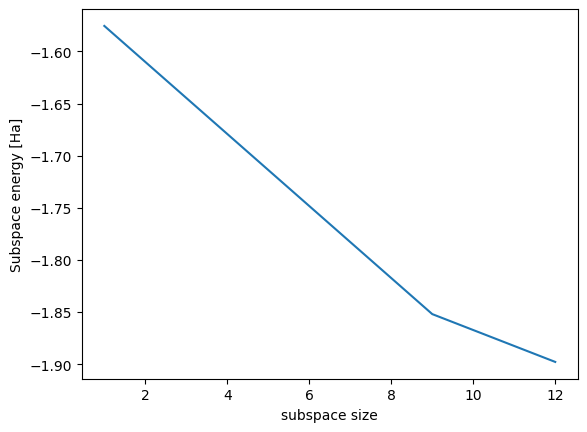

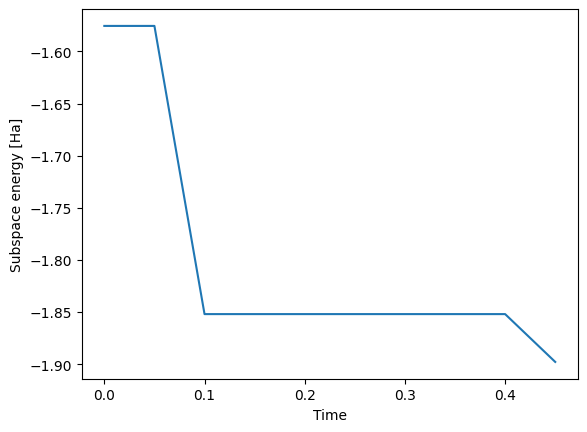

In [10]:
import numpy as np
from openfermion import get_sparse_operator
import matplotlib.pyplot as plt

# define a set of unique values
configuration_list = set()

dt = 0.05
energies = []
subspace_size = []
times = []
for t in np.arange(0, 0.5, dt):

    print('\ntime: ', t)

    sparse_state = time_evolution_trotter(t)

    probs = np.abs(sparse_state.toarray()[:,0])**2
    print('sum squares: ', sum(probs))

    def binary_strings(n, width):
        for i in range(n):
            yield format(i, f'0{width}b')[::-1] # revert to have the same order as qiskit

    tol_ampl = 1e-4
    prob_exact = {}
    for b, p  in zip(binary_strings(2**8, 8), probs):
        if p > tol_ampl:
            prob_exact[b] = p

    prob_ordered = dict(sorted(prob_exact.items(), key=lambda item: -item[1]))
    for k, v in prob_ordered.items():
        print(k, v)

    # update configuration list
    configuration_list.update(list(prob_ordered.keys()))

    energy = get_sci_energy(configuration_list)
    print('Subspace energy: ', energy)

    energies.append(energy)
    subspace_size.append(len(configuration_list))
    times.append(t)


print('\Final energy: ', energies[-1])
plt.plot(subspace_size, energies)
plt.xlabel('subspace size')
plt.ylabel('Subspace energy [Ha]')

plt.figure()
plt.plot(times, energies)
plt.xlabel('Time')
plt.ylabel('Subspace energy [Ha]')


In [11]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

te_qubit = -1j * ha_qubit

# limit the size of the circuit
te_qubit.compress(1e-2)


# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc = QuantumCircuit(8)

#reference
qc.x(0)
qc.x(1)
qc.x(2)
qc.x(3)

# time evolution
i_op = 0
for op, coef in te_qubit.terms.items():

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    if len(op) > 0:
        qc.rz(2*theta * coef.imag, op[0][0])

    for qubit, pauli in reversed(op[1:]):
        qc.cx(qubit, op[0][0])

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    qc.barrier()

print('depth', qc.depth())
# qc.draw('mpl') # BE CAREFUL uncommenting this! Large circuits consume a lot of RAM

depth 1113



time:  0.0
00001111 1.0
Subspace energy:  -1.5756164767018674

time:  0.05
00001111 0.9996
01100110 0.0003
00110011 0.0001
Subspace energy:  -1.6806619718280027

time:  0.1
00001111 0.9983
11000011 0.0006
01100110 0.0003
11001100 0.0003
00110011 0.0002
01101001 0.0001
00111100 0.0001
10010110 0.0001
Subspace energy:  -1.8519308371026528

time:  0.15000000000000002
00001111 0.9965
00110011 0.0006
11000011 0.0005
00111100 0.0005
01101001 0.0005
10011001 0.0004
11001100 0.0004
10010110 0.0003
01100110 0.0002
00011110 0.0001
Subspace energy:  -1.8519308371026528

time:  0.2
00001111 0.9945
11001100 0.0009
01101001 0.0008
11000011 0.0008
00110011 0.0007
10010110 0.0006
10011001 0.0005
00111100 0.0005
01100110 0.0005
01011010 0.0001
10100101 0.0001
Subspace energy:  -1.897780645987225

time:  0.25
00001111 0.993
00110011 0.001
11000011 0.0009
01101001 0.0009
01100110 0.0007
00111100 0.0007
10010110 0.0007
10011001 0.0006
11001100 0.0005
10100101 0.0003
01001011 0.0002
00101101 0.0002
000111

Text(0, 0.5, 'Subspace energy [Ha]')

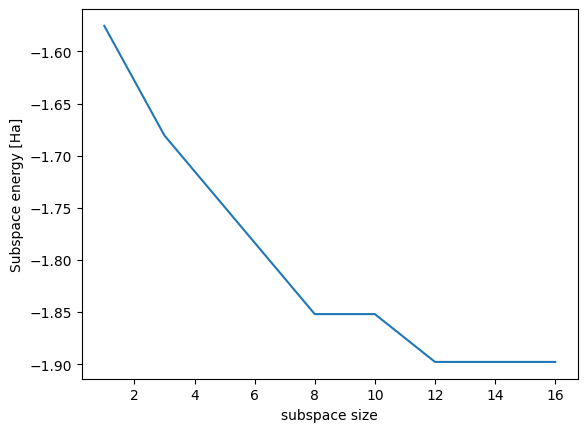

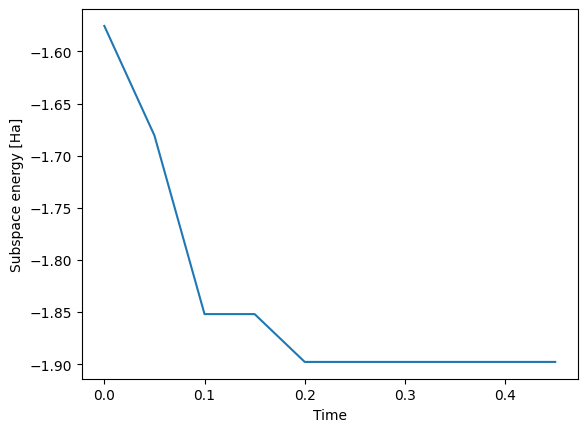

In [13]:
from qiskit.primitives import StatevectorSampler

# define a set of unique values
configuration_list = set()

dt = 0.05
energies = []
subspace_size = []
times = []
for t in np.arange(0, 0.5, dt):

    print('\ntime: ', t)

    sampler = StatevectorSampler()

    qc_meas = qc.assign_parameters([t])
    qc_meas.measure_all()

    result = sampler.run([qc_meas], shots=10000).result()
    counts = result[0].data.meas.get_counts()
    shots = sum(counts.values())

    counts_ordered = dict(sorted(counts.items(), key=lambda item: -item[1]))
    for k, v in counts_ordered.items():
        print(k, v/shots)

    # update configuration list
    configuration_list.update(list(counts_ordered.keys()))

    energy = get_sci_energy(configuration_list)
    print('Subspace energy: ', energy)

    energies.append(energy)
    subspace_size.append(len(configuration_list))
    times.append(t)

print('\nFinal energy: ', energies[-1])
plt.plot(subspace_size, energies)
plt.xlabel('subspace size')
plt.ylabel('Subspace energy [Ha]')

plt.figure()
plt.plot(times, energies)
plt.xlabel('Time')
plt.ylabel('Subspace energy [Ha]')



- Test different ranges of time
- Test different compressions for the hamiltonian